# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import WHDLDDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose
import csv

## Visualize images and masks

Total number of patches: 4940


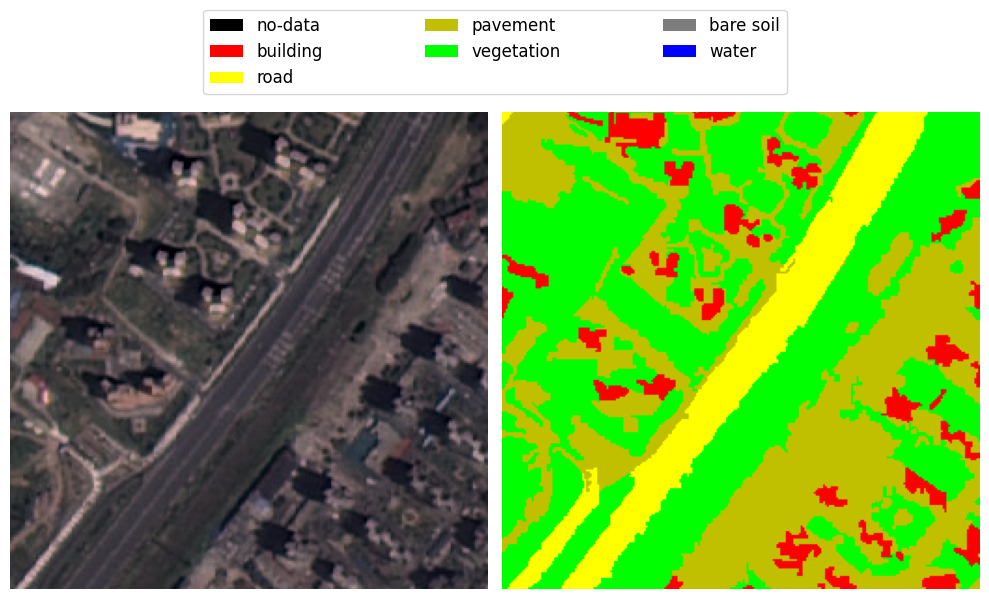

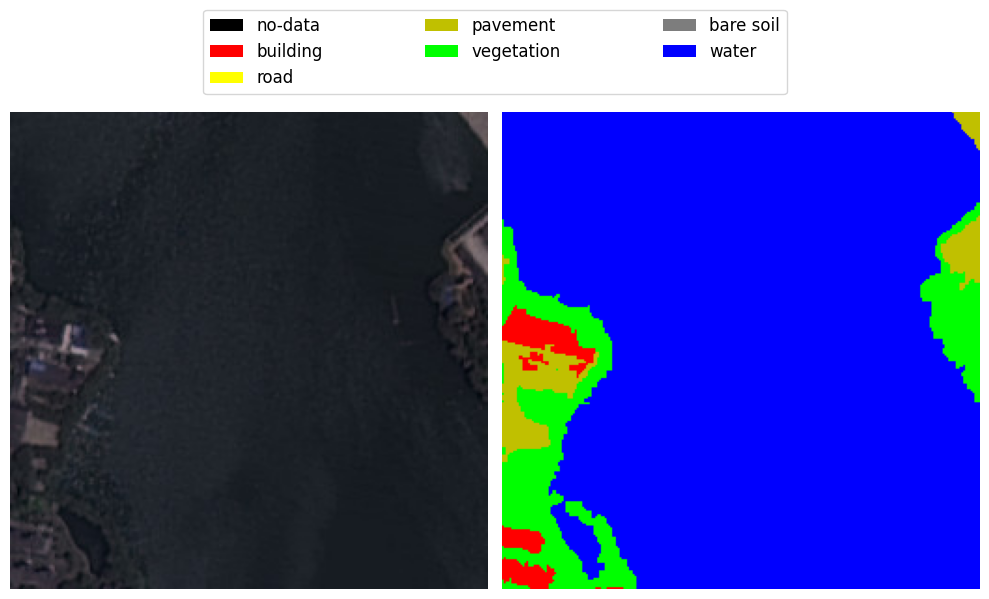

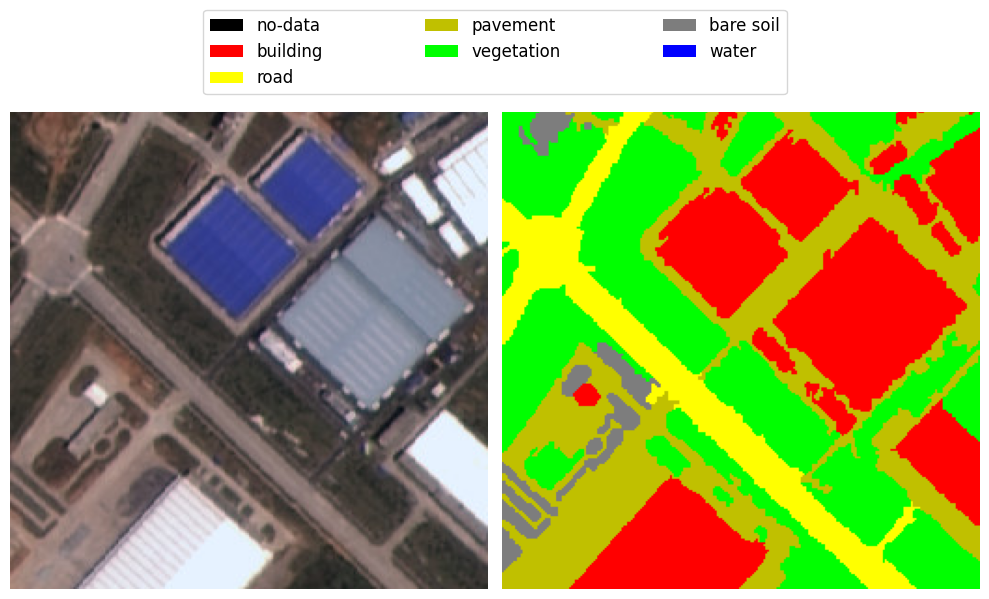

In [ ]:
dataset_config = {
    "data_dir": "./data/WHDLD"
}
dataset = WHDLDDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(350);
dataset.show_image(1500);

In [22]:
dataset.data_distribution_table()

,Number of pixels
no-data,0.0
building,35902160.0
road,13945297.0
pavement,37297256.0
vegetation,144809312.0
bare soil,13076295.0
water,78717536.0


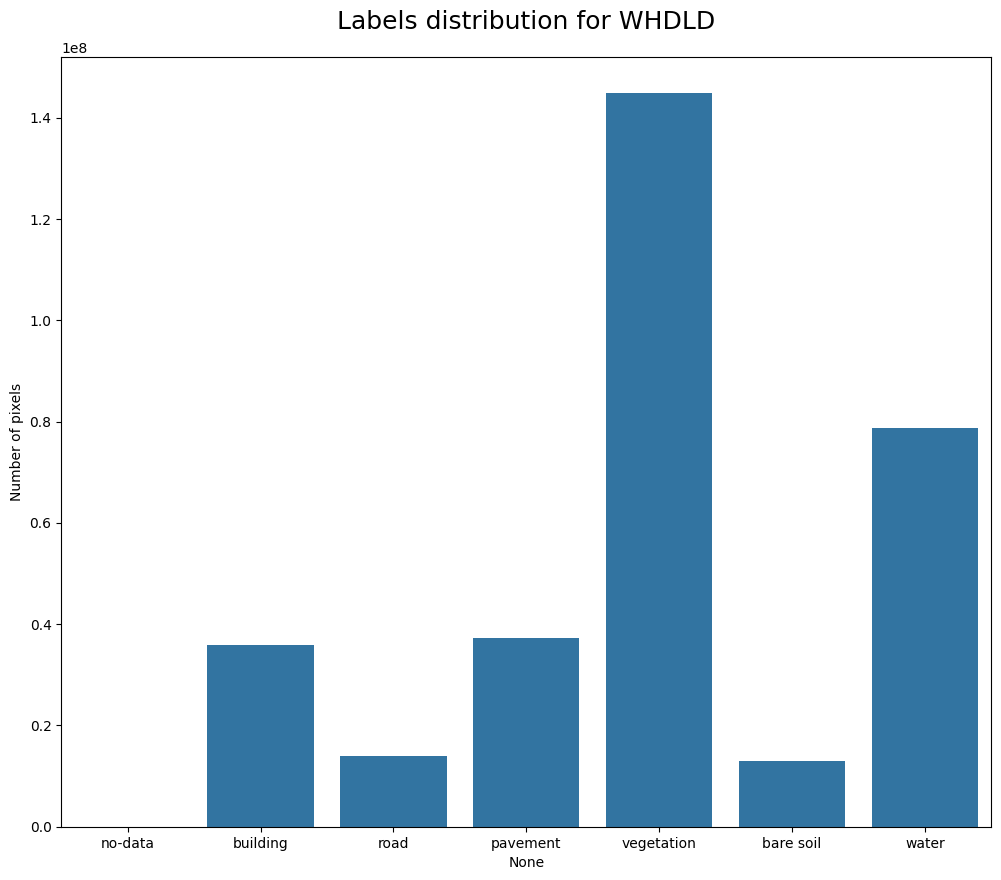

In [23]:
dataset.data_distribution_barchart();

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/WHDLD",
    "csv_file": "./data/WHDLD/whdld_train.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = WHDLDDataset(train_dataset_config)
len(train_dataset)

3952

## Create the model

In [ ]:
epochs = 10
model_directory = "./data/WHDLD"
model_config = {
    "num_classes": 7, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [6]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-03-05 14:02:59,252 INFO Starting training.
training: 100%|██████████| 494/494 [00:41<00:00, 11.78it/s]
2025-03-05 14:03:41,242 INFO epoch: 1, time: 42, loss:  0.46650
testing on train set: 100%|██████████| 494/494 [00:15<00:00, 31.16it/s]
2025-03-05 14:03:58,448 INFO IOU:0.6740887247154062, IOU mean:0.4612572912996531, IOU per Class:[0.         0.51943322 0.52168069 0.35505875 0.76759478 0.15862948
 0.90640412]
training: 100%|██████████| 494/494 [00:42<00:00, 11.75it/s]
2025-03-05 14:04:40,489 INFO epoch: 2, time: 42, loss:  0.25293
testing on train set: 100%|██████████| 494/494 [00:16<00:00, 29.67it/s]
2025-03-05 14:04:57,159 INFO IOU:0.7080756891295348, IOU mean:0.5089504009599721, IOU per Class:[0.         0.54472664 0.56672865 0.40334049 0.78806788 0.33266598
 0.92712317]
training: 100%|██████████| 494/494 [00:42<00:00, 11.61it/s]
2025-03-05 14:05:39,703 INFO epoch: 3, time: 42, loss:  0.20906
testing on train set: 100%|██████████| 494/494 [00:16<00:00, 30.67it/s]
2025-03-05 1

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/WHDLD",
    "csv_file": "./data/WHDLD/whdld_val.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = WHDLDDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/WHDLD/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

494


2025-03-05 14:12:54,181 INFO Loading checkpoint /home/dragik/data/FAIR_EO/WHDLD/checkpoint.pth.tar
2025-03-05 14:12:54,505 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/WHDLD/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 124/124 [00:02<00:00, 45.18it/s]


[{'IOU': 0.7024068312919804,
  'IOU mean': 0.5104612067419928,
  'IOU per Class': array([0.        , 0.56608485, 0.58325323, 0.41214913, 0.77574855,
         0.32203416, 0.91395853])}]

## Predictions

2025-03-10 09:48:58,054 INFO Loading checkpoint /home/dragik/data/FAIR_EO/WHDLD/checkpoint.pth.tar
2025-03-10 09:48:58,387 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/WHDLD/checkpoint.pth.tar at epoch 11


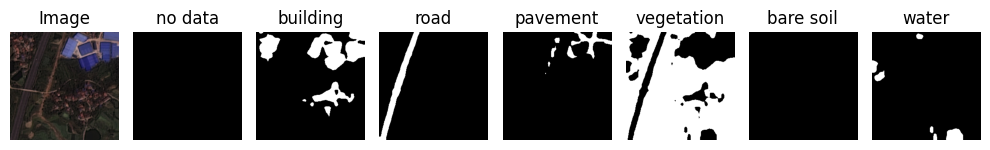

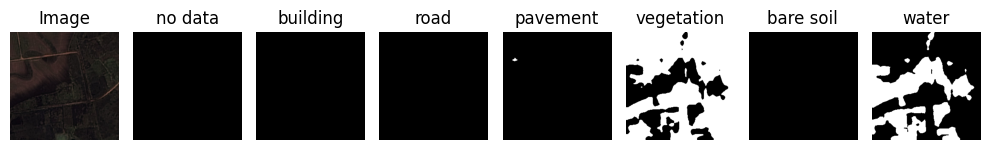

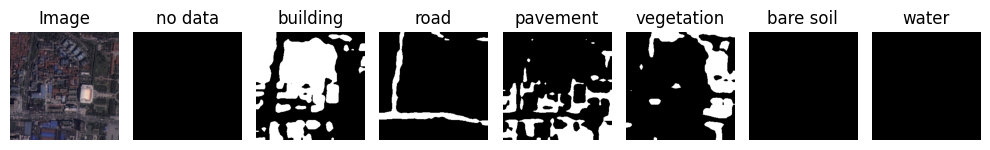

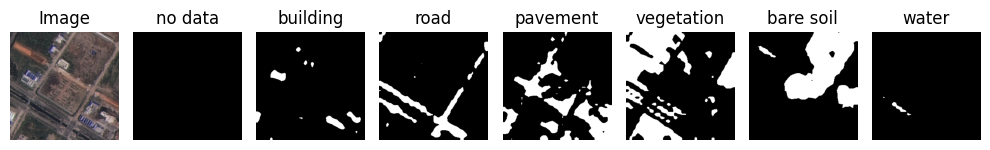

In [ ]:
model_path = "./data/WHDLD/checkpoint.pth.tar"
labels = ["no data","building","road","pavement","vegetation","bare soil","water"]
transform = MinMaxNormTranspose()
model.load_model(model_path)
csv_file = "./data/WHDLD/whdld_test.csv"

test_list = []
with open(csv_file, mode ='r')as file:
    csvFile = csv.reader(file)
    for lines in csvFile:
        test_list.append(lines[0])

image = image_loader('./data/WHDLD/' + test_list[0])
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/WHDLD/' + test_list[1])
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/WHDLD/' + test_list[10])
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/WHDLD/' + test_list[50])
fig = model.predict_masks(image, labels, transform)